# Exploring the BL-AGN and BH Masses

Ragadeepika Pucha, Stéphanie Juneau, Arjun Dey, Mar Mezcua, Yao-Yuan Mao, and others ...

This notebook explores the BL-AGN candidates and BH Masses. It also creates the BL-AGN catalog for further analysis.

In [1]:
import numpy as np

from astropy.table import Table, join, Column, vstack

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import bpt
import utils

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from glob import glob

from desitarget.targetmask import desi_mask
from desitarget.sv1.sv1_targetmask import desi_mask as sv1_desi_mask
from desitarget.sv2.sv2_targetmask import desi_mask as sv2_desi_mask
from desitarget.sv3.sv3_targetmask import desi_mask as sv3_desi_mask

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':22,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':2.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.0,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.0,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
t = Table.read('../catalogs/iron-selection-v2.3.fits')
len(t)

6099572

In [4]:
## VI Flags

vi_out = glob('../02_Analysis/VI_Files/*.txt')

tables = []

for file in vi_out:
    tab = Table.read(file, format = 'ascii')
    tables.append(tab)

t_vi = vstack(tables)
t = join(t, t_vi, keys = ['TARGETID'], join_type = 'left')
t['VI_FLAG'].fill_value = 0
t = t.filled()

In [5]:
## Stellar Mass related variables

logmass = t['LOGM'].data
lomass = (logmass <= 9.5)
himass = (logmass > 9.5)

len(t[lomass]), len(t[himass])

(987987, 5111585)

In [6]:
## Morphology related variables
mtype = t['TYPE'].astype(str).data
ser = t['SERSIC'].data

is_psf = mtype == 'PSF'
is_late = ((mtype == 'REX')|(mtype == 'EXP')|((mtype == 'SER')&(ser <= 2)))
is_early = ~is_psf & ~is_late

In [7]:
## Double-Peaked Emission Line Flags
is_sii_dbl = t['SII_DBL_FLAG'].data
is_oiii_dbl = t['OIII_DBL_FLAG'].data

len(t[is_sii_dbl]), len(t[is_oiii_dbl])

(24735, 15702)

In [8]:
## Emission-line measurements -- Narrow only and sum

## Narrow Only
nii_n = t['NII6583_FLUX'].data
nii_snr_n = nii_n/t['NII6583_FLUX_ERR'].data
nii_aon = t['NII6583_AMPLITUDE'].data/t['NII_HA_NOISE'].data

oiii_n = t['OIII5007_FLUX'].data
oiii_snr_n = oiii_n/t['OIII5007_FLUX_ERR'].data
oiii_aon = t['OIII5007_AMPLITUDE'].data/t['OIII_NOISE'].data

ha_n = t['HA_N_FLUX'].data
ha_snr_n = ha_n/t['HA_N_FLUX_ERR'].data
ha_aon = t['HA_N_AMPLITUDE'].data/t['NII_HA_NOISE'].data

hb_n = t['HB_N_FLUX'].data
hb_snr_n = hb_n/t['HB_N_FLUX_ERR'].data
hb_aon = t['HB_N_AMPLITUDE'].data/t['HB_NOISE']


## Sum
nii_sum = t['NII6583_FLUX'].data + t['NII6583_OUT_FLUX'].data
nii_snr_sum = nii_sum/np.sqrt((t['NII6583_FLUX_ERR'].data**2) + (t['NII6583_OUT_FLUX_ERR'].data**2))

oiii_sum = t['OIII5007_FLUX'].data + t['OIII5007_OUT_FLUX'].data
oiii_snr_sum = oiii_sum/np.sqrt((t['OIII5007_FLUX_ERR'].data**2) + (t['OIII5007_OUT_FLUX_ERR'].data**2))

ha_sum = t['HA_N_FLUX'].data + t['HA_OUT_FLUX'].data
ha_snr_sum = ha_sum/np.sqrt((t['HA_N_FLUX_ERR'].data**2) + (t['HA_OUT_FLUX_ERR'].data**2))

hb_sum = t['HB_N_FLUX'].data + t['HB_OUT_FLUX'].data
hb_snr_sum = hb_sum/np.sqrt((t['HB_N_FLUX_ERR'].data**2) + (t['HB_OUT_FLUX_ERR'].data**2))

In [9]:
## Emission-line measurements

## Empty arrays
nii, nii_snr = np.zeros(len(t)), np.zeros(len(t))
oiii, oiii_snr = np.zeros(len(t)), np.zeros(len(t))
ha, ha_snr = np.zeros(len(t)), np.zeros(len(t))
hb, hb_snr = np.zeros(len(t)), np.zeros(len(t))

## [OIII] Condition
oiii[is_oiii_dbl], oiii[~is_oiii_dbl] = oiii_sum[is_oiii_dbl], oiii_n[~is_oiii_dbl]
oiii_snr[is_oiii_dbl], oiii_snr[~is_oiii_dbl] = oiii_snr_sum[is_oiii_dbl], oiii_snr_n[~is_oiii_dbl]

## [NII]+Ha Condition
nii[is_sii_dbl], nii[~is_sii_dbl] = nii_sum[is_sii_dbl], nii_n[~is_sii_dbl]
nii_snr[is_sii_dbl], nii_snr[~is_sii_dbl] = nii_snr_sum[is_sii_dbl], nii_snr_n[~is_sii_dbl]

ha[is_sii_dbl], ha[~is_sii_dbl] = ha_sum[is_sii_dbl], ha_n[~is_sii_dbl]
ha_snr[is_sii_dbl], ha_snr[~is_sii_dbl] = ha_snr_sum[is_sii_dbl], ha_snr_n[~is_sii_dbl]

hb[is_sii_dbl], hb[~is_sii_dbl] = hb_sum[is_sii_dbl], hb_n[~is_sii_dbl]
hb_snr[is_sii_dbl], hb_snr[~is_sii_dbl] = hb_snr_sum[is_sii_dbl], hb_snr_n[~is_sii_dbl]

nii_ha = np.log10(nii/ha)
oiii_hb = np.log10(oiii/hb)

In [10]:
is_agn, is_comp, is_sf = bpt.Classify_NII_BPT(nii_ha, oiii_hb)

In [11]:
## BL Related Variables

z = t['Z'].data
ha_b = t['HA_B_FLUX'].data
ha_b_err = t['HA_B_FLUX_ERR'].data
ha_b_snr = ha_b/ha_b_err
ha_b_aon = t['HA_B_AMPLITUDE'].data/t['NII_HA_NOISE'].data
ha_b_sig = t['HA_B_SIGMA'].data
ha_b_sig_err = t['HA_B_SIGMA_ERR'].data
ha_b_sig_snr = ha_b_sig/ha_b_sig_err
per_broad = t['PROB_BROAD'].data

ha_b_lum, ha_b_lum_err = utils.Flux_to_Luminosity(ha_b*1e-17, z, ha_b_err*1e-17)
ha_b_fwhm, ha_b_fwhm_err = utils.sigma_to_fwhm(ha_b_sig, ha_b_sig_err)
bh_mass, bh_mass_err1 = utils.calculate_bh_masses(ha_b_lum, ha_b_fwhm, ha_b_lum_err, ha_b_fwhm_err)
bh_mass_err = np.sqrt((bh_mass_err1**2)+(0.5**2))

is_imbh = (bh_mass <= 6)

In [12]:
## Bolometric Luminosity and Eddington Ratio 
## [OIII] Luminosity
L_oiii = utils.Flux_to_Luminosity(oiii*1e-17, z)

## Using Moran et al. (2014) - Lbol = 1000*L_oiii
L_bol = 1000*L_oiii

## Eddington Ratio
lam_edd = utils.calculate_eddington_ratio(bh_mass, L_bol)
log_lamedd = np.log10(lam_edd)

In [13]:
## Cuts
bpt_cut = (nii_snr >= 3)&(oiii_snr >= 3)&(ha_snr >= 3)&(hb_snr >= 1)&(hb_aon >= 1)
bl_cut = (ha_b_fwhm >= 300)&(ha_b_fwhm < 15000)&(ha_b_snr >= 3)&(ha_b_sig_snr >= 3)&(ha_b_aon >= 2)&(per_broad >= 80)&(t['HA_B_SIGMA'].data > t['HA_N_SIGMA'].data)&(t['HA_N_AMPLITUDE'].data > t['HA_B_AMPLITUDE'].data)

is_bl = bpt_cut&bl_cut
is_nl = bpt_cut&~bl_cut

In [14]:
## VI Flags: Set VI of NL Candidates as -1
t['VI_FLAG'][is_nl] = np.array([-1]*len(t[is_nl]))

fwhm_lt1000 = (ha_b_fwhm < 1000)
vi_flag = t['VI_FLAG'].data
vi0 = vi_flag == 0
vi1 = vi_flag == 1
vi2 = vi_flag == 2
vi3 = vi_flag == 3
vi4 = vi_flag == 4

In [15]:
### VI Flag Numbers
print ('Number of BL-AGN with FWHM ≤ 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000]))
print ('VI Flag = 0 -- Good fits: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi0]))
print ('VI Flag = 1 -- Maybe fits: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi1]))
print ('VI Flag = 2 -- Maybe second/outflow component: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi2]))
print ('VI Flag = 3 -- Bad Fits VI-ed: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi3]))
print ('VI Flag = 4 -- Bad Fits Stack: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi4]))

Number of BL-AGN with FWHM ≤ 1000 km/s:  2309
VI Flag = 0 -- Good fits:  665
VI Flag = 1 -- Maybe fits:  161
VI Flag = 2 -- Maybe second/outflow component:  305
VI Flag = 3 -- Bad Fits VI-ed:  19
VI Flag = 4 -- Bad Fits Stack:  1159


In [16]:
### VI Flag Numbers -- PSF
print ('Number of BL-AGN with FWHM ≤ 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&is_psf]))
print ('VI Flag = 0 -- Good fits: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi0&is_psf]))
print ('VI Flag = 1 -- Maybe fits: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi1&is_psf]))
print ('VI Flag = 2 -- Maybe second/outflow component: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi2&is_psf]))
print ('VI Flag = 3 -- Bad Fits VI-ed: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi3&is_psf]))
print ('VI Flag = 4 -- Bad Fits Stack: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&vi4&is_psf]))

Number of BL-AGN with FWHM ≤ 1000 km/s:  210
VI Flag = 0 -- Good fits:  74
VI Flag = 1 -- Maybe fits:  44
VI Flag = 2 -- Maybe second/outflow component:  84
VI Flag = 3 -- Bad Fits VI-ed:  8
VI Flag = 4 -- Bad Fits Stack:  0


In [17]:
is_def = (t['NII_HA_SII_NDOF'].data == 0)&(t['HB_OIII_NDOF'].data == 0)
is_ebl = (t['HB_NDOF'].data == 0)&(t['OIII_NDOF'].data == 0)&(t['NII_HA_NDOF'].data == 0)&(t['SII_NDOF'].data == 0)

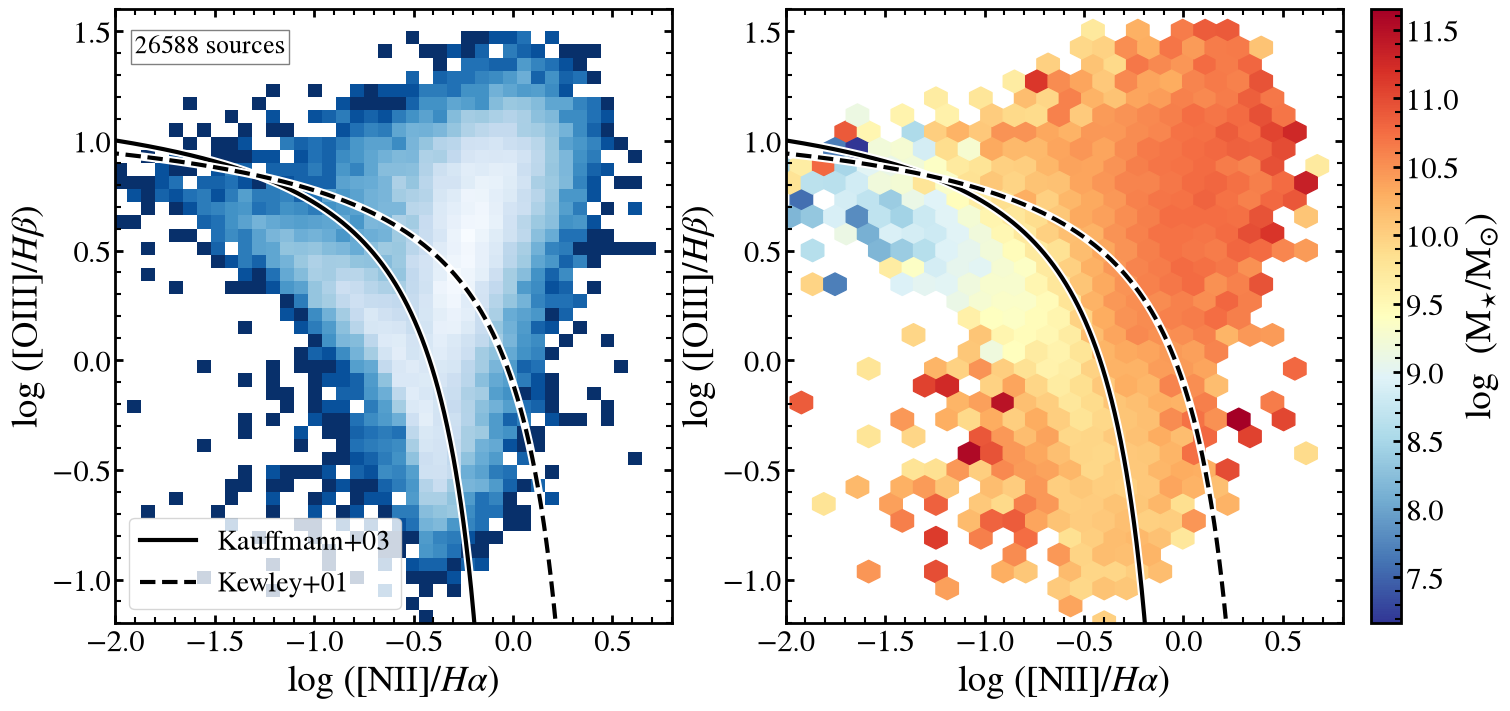

In [18]:
fig = plt.figure(figsize = (15, 7), constrained_layout = True)
gs = fig.add_gridspec(5, 6)

ax1 = fig.add_subplot(gs[:, 0:3])
ax2 = fig.add_subplot(gs[:, 3:], sharex = ax1, sharey = ax1)

ax1.hist2d(nii_ha[is_bl], oiii_hb[is_bl], bins = 50, norm = LogNorm(), range = [[-2.5, 1], [-1.5, 1.5]], cmap = 'Blues_r')
bpt.Plot_NII_BPT_Lines(axs = ax1, Schawinsky = False, legend = True)
ax1.text(-1.9, 1.4, f'{len(nii_ha[is_bl])} sources', fontsize = 18, bbox = dict(facecolor = 'none', edgecolor = 'grey', pad = 3))
ax1.set(xlabel = 'log ([NII]/$H\\alpha$)', ylabel = 'log ([OIII]/$H\\beta$)')

bpt_plot = ax2.hexbin(nii_ha[is_bl], oiii_hb[is_bl], C = logmass[is_bl], cmap = 'RdYlBu_r', gridsize=35)
fig.colorbar(bpt_plot, label = '$\\rm\log~(M_{\star}/M_{\odot})$')
bpt.Plot_NII_BPT_Lines(axs = ax2, Schawinsky = False)
ax2.set(xlabel = 'log ([NII]/$H\\alpha$)', ylabel = 'log ([OIII]/$H\\beta$)', xlim = [-2, 0.8], ylim = [-1.2, 1.6])

plt.show()

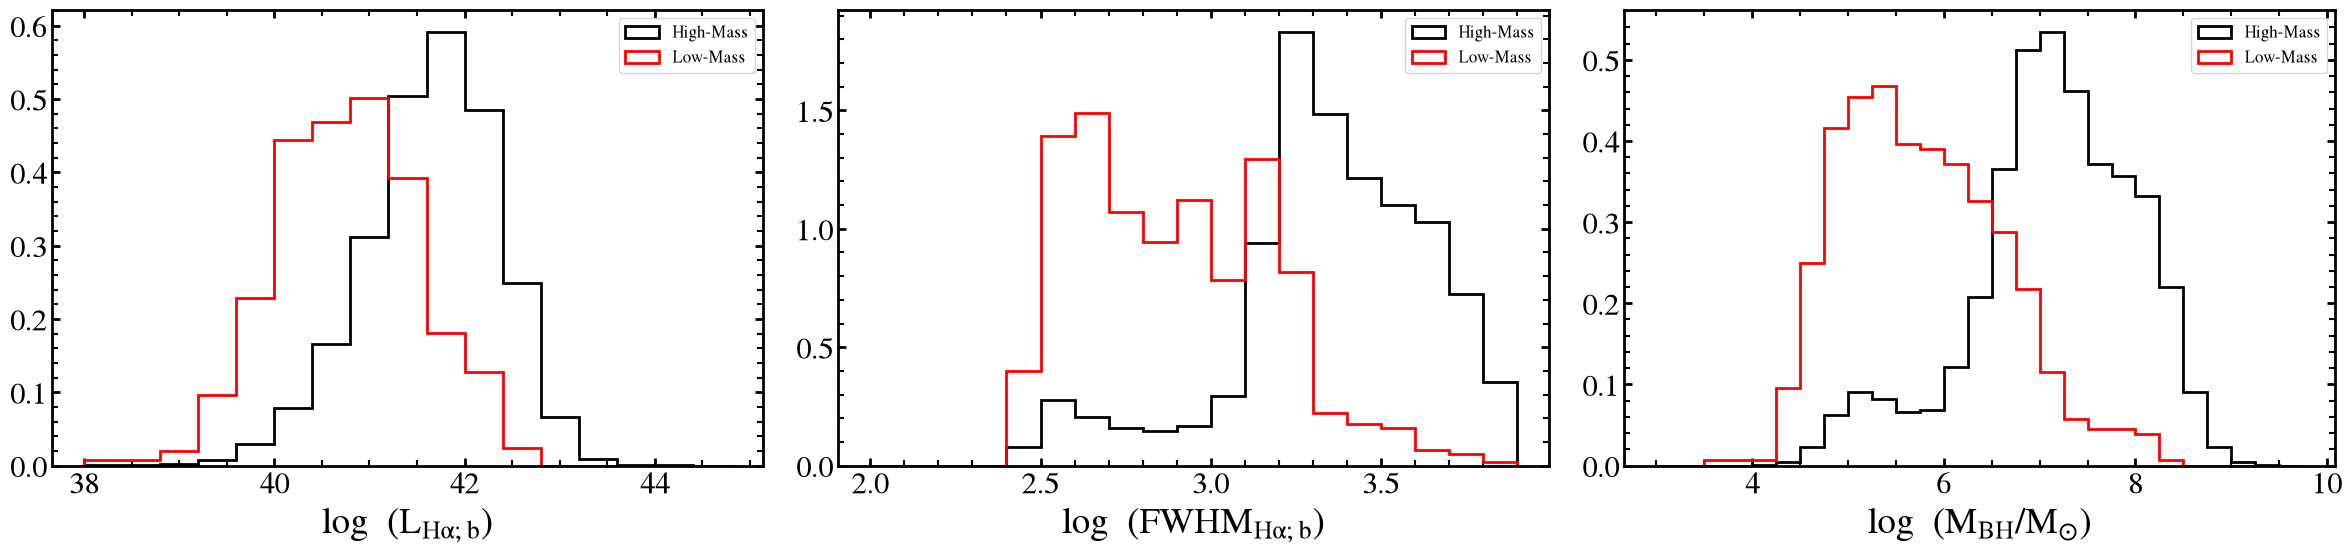

In [19]:
plt.figure(figsize = (24, 6))

plt.subplot2grid((1,3), (0,0))
bins = np.arange(38, 45, 0.4)
plt.hist(np.log10(ha_b_lum)[is_bl&(is_agn|is_comp)&himass], bins = bins, histtype = 'step', color = 'k', lw = 2.0, label = 'High-Mass', density = True)
plt.hist(np.log10(ha_b_lum)[is_bl&(is_agn|is_comp)&lomass], bins = bins, histtype = 'step', color = 'r', lw = 2.0, label = 'Low-Mass', density = True)
plt.xlabel('$\\rm\log~(L_{H\\alpha;b})$')
plt.legend(fontsize = 12)

plt.subplot2grid((1,3), (0,1))
bins = np.arange(2, 4, 0.1)
plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&himass], bins = bins, histtype = 'step', color = 'k', lw = 2.0, label = 'High-Mass', density = True)
plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&lomass], bins = bins, histtype = 'step', color = 'r', lw = 2.0, label = 'Low-Mass', density = True)
plt.xlabel('$\\rm\log~(FWHM_{H\\alpha;b})$')
plt.legend(fontsize = 12)

plt.subplot2grid((1,3), (0,2))
bins = np.arange(3, 10, 0.25)
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&himass], bins = bins, histtype = 'step', color = 'k', lw = 2.0, label = 'High-Mass', density = True)
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&lomass], bins = bins, histtype = 'step', color = 'r', lw = 2.0, label = 'Low-Mass', density = True)
plt.xlabel('$\\rm\log~(M_{BH}/M_{\odot})$')
plt.legend(fontsize = 12)

plt.tight_layout()

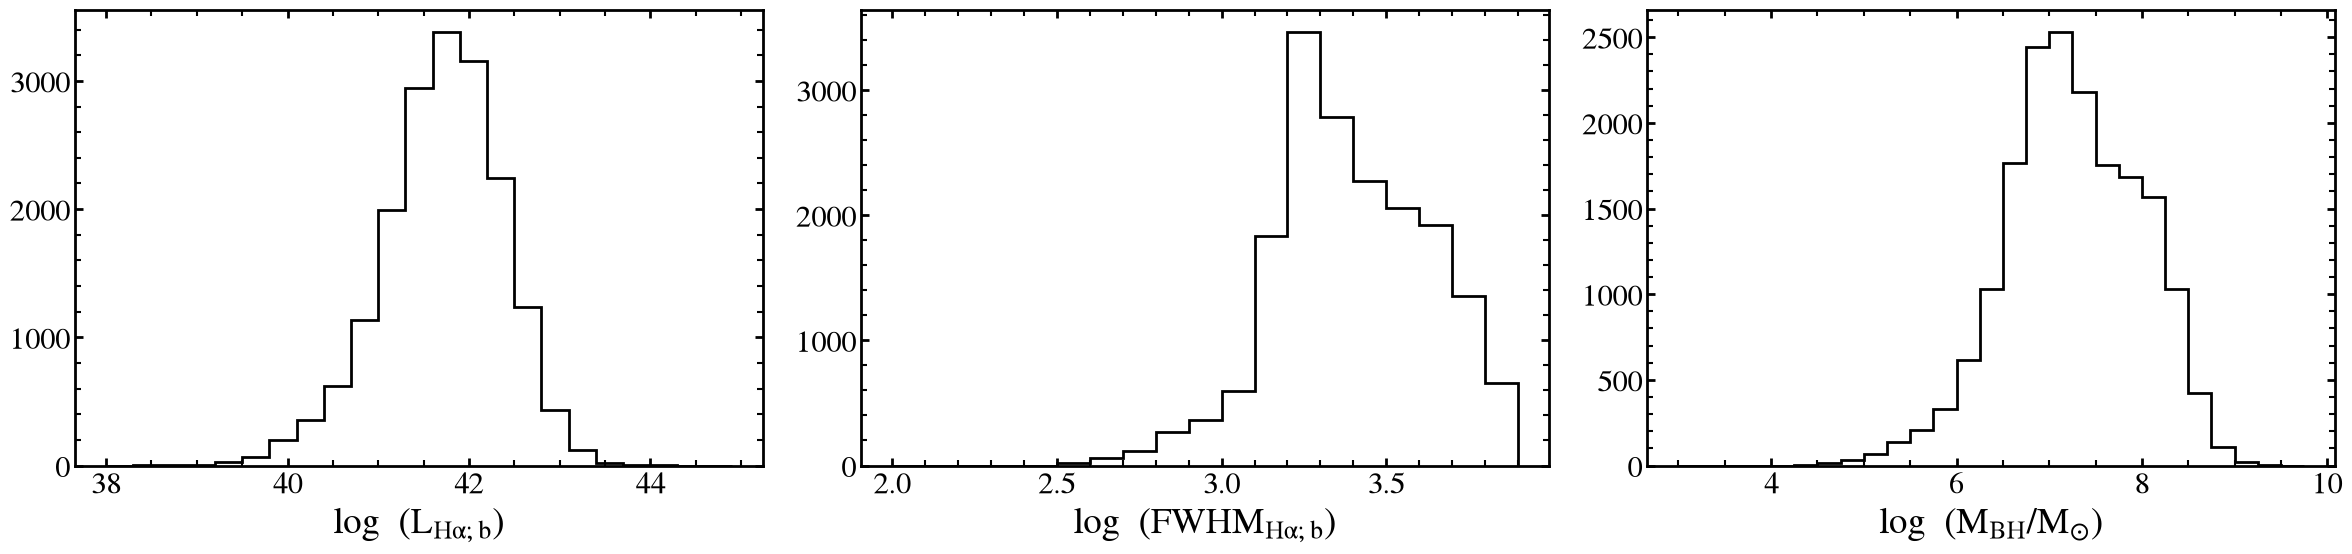

In [20]:
plt.figure(figsize = (24, 6))

plt.subplot2grid((1,3), (0,0))
bins = np.arange(38, 45, 0.3)
plt.hist(np.log10(ha_b_lum)[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'step', color = 'k', lw = 2.0)#, log = True)
plt.xlabel('$\\rm\log~(L_{H\\alpha;b})$')

plt.subplot2grid((1,3), (0,1))
bins = np.arange(2, 4, 0.1)
plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'step', color = 'k', lw = 2.0, label = 'High-Mass')#, log = True)
plt.xlabel('$\\rm\log~(FWHM_{H\\alpha;b})$')

plt.subplot2grid((1,3), (0,2))
bins = np.arange(3, 10, 0.25)
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'step', color = 'k', lw = 2.0)
plt.xlabel('$\\rm\log~(M_{BH}/M_{\odot})$')

plt.tight_layout()

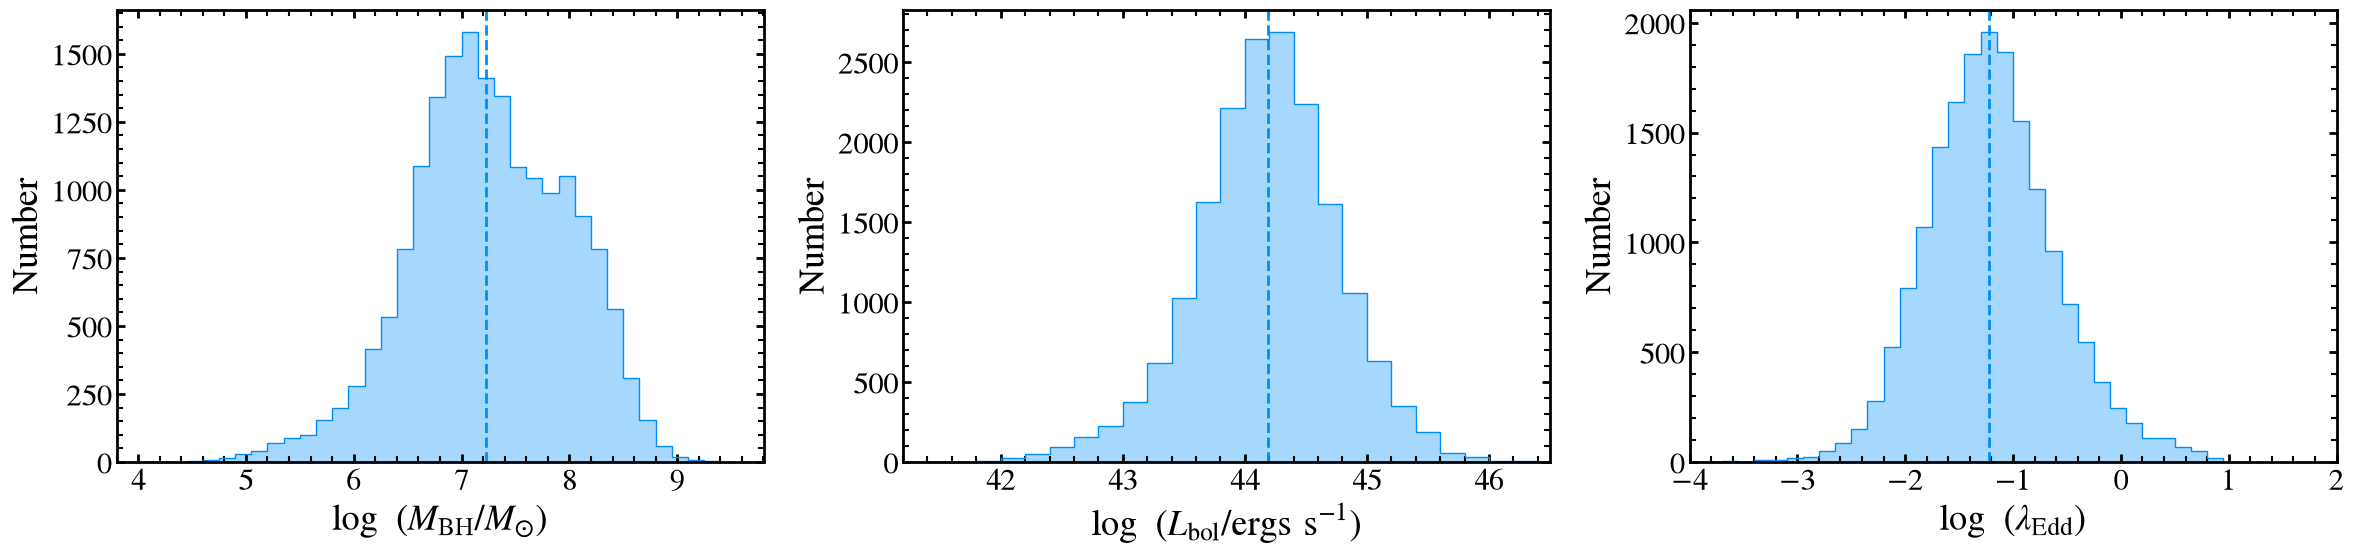

In [21]:
plt.figure(figsize = (24, 6))

plt.subplot2grid((1,3), (0,0))
bins = np.arange(4, 9.5, 0.15)
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'step', color = '#008df9')
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'bar', color = '#008df9', alpha = 0.35)
plt.axvline(np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)]), color = '#008df9', lw = 2.0, ls = '--')
plt.xlabel('$\log~(M_{\\rm BH}/M_{\odot})$', fontsize = 26)
plt.ylabel('Number', fontsize = 26)
plt.xlim([3.8, 9.8])

plt.subplot2grid((1,3), (0,1))
bins = np.arange(40, 47, 0.2)
plt.hist(np.log10(L_bol)[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'step', color = '#008df9')
plt.hist(np.log10(L_bol)[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'bar', color = '#008df9', alpha = 0.35)
plt.axvline(np.median(np.log10(L_bol)[is_bl&(is_agn|is_comp)&(vi0|vi1)]), color = '#008df9', lw = 2.0, ls = '--')
plt.xlabel('$\log~(L_{\\rm bol}/\\rm ergs~s^{-1})$', fontsize = 26)
plt.ylabel('Number', fontsize = 26)
plt.xlim([41.2, 46.5])

plt.subplot2grid((1,3), (0,2))
bins = np.arange(-4, 1, 0.15)
plt.hist(log_lamedd[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'step', color = '#008df9')
plt.hist(log_lamedd[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bins, histtype = 'bar', color = '#008df9', alpha = 0.35)
plt.axvline(np.median(log_lamedd[is_bl&(is_agn|is_comp)&(vi0|vi1)]), color = '#008df9', lw = 2.0, ls = '--')
plt.xlabel('$\log~(\lambda_{\\rm Edd})$', fontsize = 26)
plt.ylabel('Number', fontsize = 26)
plt.xlim([-4, 2])

plt.tight_layout()
# plt.savefig('bhprops_dist.png')

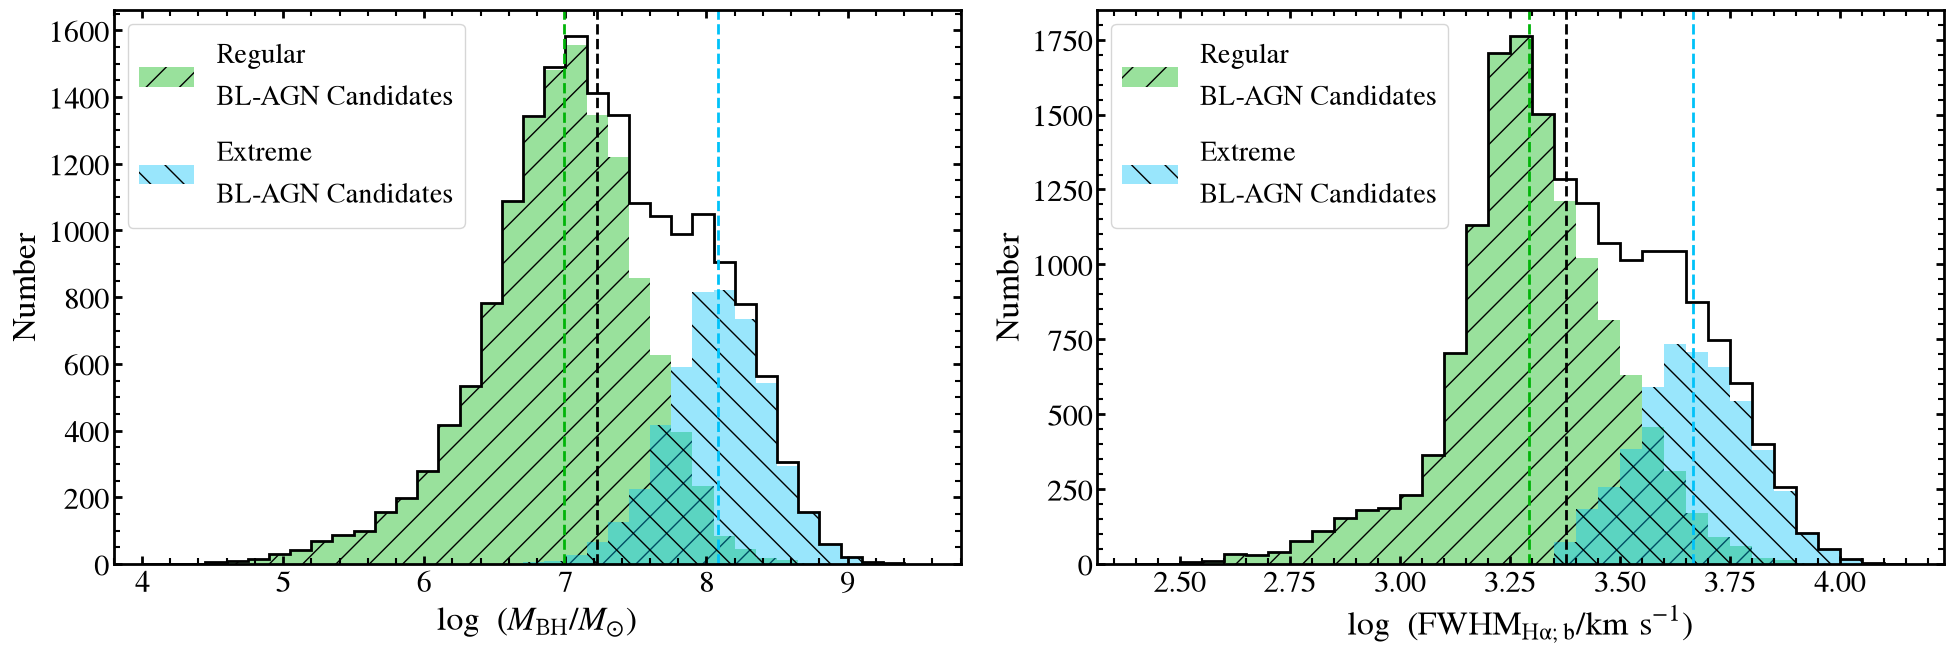

In [22]:
plt.figure(figsize = (20, 7))

plt.subplot2grid((1,2), (0,0))
bh_bins = np.arange(4, 9.5, 0.15)
bh_hist = plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = bh_bins, histtype = 'step', color = 'k', lw = 2.0)
bh_hist1 = plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def], bins = bh_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00b408', hatch = '/', label = 'Regular\nBL-AGN Candidates')
bh_hist2 = plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl], bins = bh_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00c2f9', hatch = '\\', label = 'Extreme\nBL-AGN Candidates')
plt.axvline(np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)]), color = 'k', lw = 2.0, ls = '--')
plt.axvline(np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), color = '#00b408', lw = 2.0, ls = '--')
plt.axvline(np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), color = '#00c2f9', lw = 2.0, ls = '--')
plt.xlabel('$\log~(M_{\\rm BH}/M_{\odot})$', fontsize = 24)
plt.ylabel('Number', fontsize = 24)
plt.legend(loc = 'upper left', fontsize = 20)
plt.xlim([3.8, 9.8])

plt.subplot2grid((1,2), (0,1))
ha_bins = np.arange(2.4, 4.2, 0.05)
ha_hist = plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)], bins = ha_bins, histtype = 'step', color = 'k', lw = 2.0)
ha_hist1 = plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def], bins = ha_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00b408', hatch = '/', label = 'Regular \nBL-AGN Candidates')
ha_hist2 = plt.hist(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl], bins = ha_bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00c2f9', hatch = '\\', label = 'Extreme \nBL-AGN Candidates')
plt.axvline(np.median(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)]), color = 'k', lw = 2.0, ls = '--')
plt.axvline(np.median(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), color = '#00b408', lw = 2.0, ls = '--')
plt.axvline(np.median(np.log10(ha_b_fwhm)[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), color = '#00c2f9', lw = 2.0, ls = '--')
plt.xlabel('$\log~(\\rm FWHM_{H\\alpha;b}/km~s^{-1})$', fontsize = 24)
plt.legend(loc = 'upper left', fontsize = 20)
plt.ylabel('Number', fontsize = 24)

plt.tight_layout()
# plt.savefig('bhmass_dist.png')

In [23]:
min(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), max(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), np.median(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def])

(np.float64(327.00975042780624),
 np.float64(9258.49890289375),
 np.float64(1967.4489305384932))

In [24]:
min(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), max(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), np.median(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl])

(np.float64(2357.726344141612),
 np.float64(13020.751231467944),
 np.float64(4651.953823190294))

In [25]:
min(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)]), max(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), np.median(ha_b_fwhm[is_bl&(is_agn|is_comp)&(vi0|vi1)])

(np.float64(327.00975042780624),
 np.float64(13020.751231467944),
 np.float64(2392.555822106484))

In [26]:
# t1 = Table()
# t1.add_column(Column(bh_bins[0:-1], name = 'LOG_MBH', dtype = np.float32))
# t1.add_column(Column(bh_hist[0], name = 'NUM_TOTAL', dtype = np.int))
# t1.add_column(Column(bh_hist1[0], name = 'NUM_REG_BLAGN', dtype = np.int))
# t1.add_column(Column(bh_hist2[0], name = 'NUM_EXT_BLAGN', dtype = np.int))

# t1.write('../catalogs/paper_figures/Fig04a_bhmass_hist.csv', format = 'csv', overwrite = True)

# t2 = Table()
# t2.add_column(Column(ha_bins[0:-1], name = 'LOG_HA_B_FWHM', dtype = np.float32))
# t2.add_column(Column(ha_hist[0], name = 'NUM_TOTAL', dtype = np.int))
# t2.add_column(Column(ha_hist1[0], name = 'NUM_REG_BLAGN', dtype = np.int))
# t2.add_column(Column(ha_hist2[0], name = 'NUM_EXT_BLAGN', dtype = np.int))

# t2.write('../catalogs/paper_figures/Fig04b_ha_b_fwhm_hist.csv', format = 'csv', overwrite = True)

In [27]:
is_bgs = (t['DESI_TARGET'].data & desi_mask['BGS_ANY'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['BGS_ANY'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['BGS_ANY'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['BGS_ANY'] != 0))
is_mws = (t['DESI_TARGET'].data & desi_mask['MWS_ANY'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['MWS_ANY'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['MWS_ANY'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['MWS_ANY'] != 0))
is_lrg = (t['DESI_TARGET'].data & desi_mask['LRG'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['LRG'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['LRG'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['LRG'] != 0))
is_elg = (t['DESI_TARGET'].data & desi_mask['ELG'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['ELG'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['ELG'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['ELG'] != 0))
is_qso = (t['DESI_TARGET'].data & desi_mask['QSO'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['QSO'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['QSO'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['QSO'] != 0))
is_scnd = (t['DESI_TARGET'].data & desi_mask['SCND_ANY'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['SCND_ANY'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['SCND_ANY'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['SCND_ANY'] != 0))

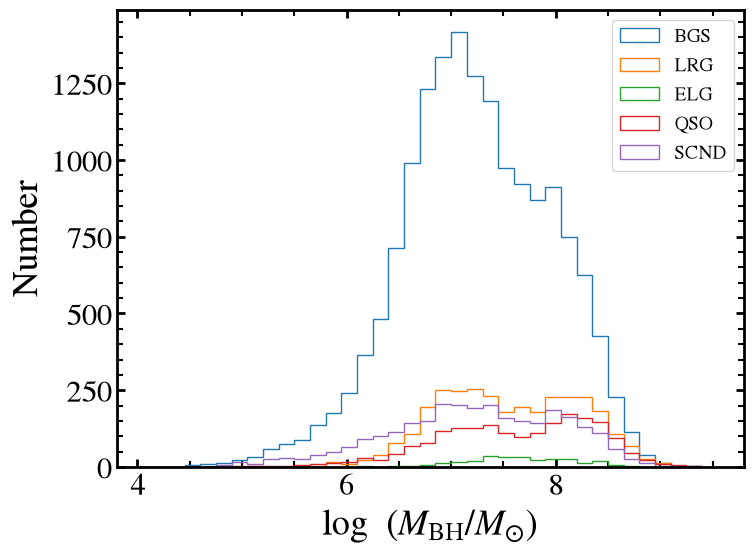

In [28]:
plt.figure(figsize = (8, 6))

bins = np.arange(4, 9.5, 0.15)
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_bgs], bins = bins, histtype = 'step', color = 'C0', label = 'BGS')
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_lrg], bins = bins, histtype = 'step', color = 'C1', label = 'LRG')
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_elg], bins = bins, histtype = 'step', color = 'C2', label = 'ELG')
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_qso], bins = bins, histtype = 'step', color = 'C3', label = 'QSO')
plt.hist(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_scnd], bins = bins, histtype = 'step', color = 'C4', label = 'SCND')
plt.legend(fontsize = 14)
plt.xlabel('$\log~(M_{\\rm BH}/M_{\odot})$', fontsize = 26)
plt.ylabel('Number', fontsize = 26)
plt.xlim([3.8, 9.8])

plt.tight_layout()
# plt.savefig('bhmass_dist.png')

## Numbers

In [29]:
print ('Number of BL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print ('Number of Regular BL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]))
print ('Number of EBL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]))

Number of BL-AGN Candidates:  17949
Number of Regular BL-AGN Candidates:  13026
Number of EBL-AGN Candidates:  4923


In [30]:
min(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), max(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def])

(np.float64(4.439989372840381),
 np.float64(8.958192231731303),
 np.float64(6.988996579702895))

In [31]:
min(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), max(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl])

(np.float64(6.616094813785569),
 np.float64(9.400460767285272),
 np.float64(8.083200405021547))

In [32]:
print ('Number of BGS Regular BL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_bgs]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_bgs])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), 1), '%')
print ('Number of LRG Regular BL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_lrg]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_lrg])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), 1), '%')
print ('Number of ELG Regular BL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_elg]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_elg])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), 1), '%')
print ('Number of QSO Regular BL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_qso]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_qso])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), 1), '%')
print ('Number of SCND Regular BL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_scnd]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def&is_scnd])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_def]), 1), '%')

Number of BGS Regular BL-AGN Candidates:  11627 89.3 %
Number of LRG Regular BL-AGN Candidates:  1943 14.9 %
Number of ELG Regular BL-AGN Candidates:  201 1.5 %
Number of QSO Regular BL-AGN Candidates:  1055 8.1 %
Number of SCND Regular BL-AGN Candidates:  1881 14.4 %


In [33]:
print ('Number of BGS EBL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_bgs]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_bgs])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), 1), '%')
print ('Number of LRG EBL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_lrg]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_lrg])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), 1), '%')
print ('Number of ELG EBL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_elg]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_elg])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), 1), '%')
print ('Number of QSO EBL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_qso]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_qso])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), 1), '%')
print ('Number of SCND EBL-AGN Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_scnd]), round(len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl&is_scnd])*100/len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_ebl]), 1), '%')

Number of BGS EBL-AGN Candidates:  4112 83.5 %
Number of LRG EBL-AGN Candidates:  1150 23.4 %
Number of ELG EBL-AGN Candidates:  77 1.6 %
Number of QSO EBL-AGN Candidates:  867 17.6 %
Number of SCND EBL-AGN Candidates:  931 18.9 %


In [34]:
print ('Total Number of BL-AGN before VI: ', len(t[is_bl&(is_agn|is_comp)]))
print ('Total Number of BL-AGN after VI: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print ('Total Number of Confident BL-AGN: ', len(t[is_bl&(is_agn|is_comp)&vi0]))
print ('Total Number of Tentative BL-AGN: ', len(t[is_bl&(is_agn|is_comp)&vi1]))
print ('------------------------------------------------------------------------')
print ('Number of Extended BL-AGN Sources: ', len(t[is_bl&(is_agn|is_comp)&~is_psf]))
print ('Number of Point BL-AGN Sources: ', len(t[is_bl&(is_agn|is_comp)&is_psf]))
print ('------------------------------------------------------------------------')

Total Number of BL-AGN before VI:  19432
Total Number of BL-AGN after VI:  17949
Total Number of Confident BL-AGN:  17788
Total Number of Tentative BL-AGN:  161
------------------------------------------------------------------------
Number of Extended BL-AGN Sources:  17262
Number of Point BL-AGN Sources:  2170
------------------------------------------------------------------------


In [35]:
print ('BL-AGN with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000]))
print ('Confident BL-AGN with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&vi0&fwhm_lt1000]))
print ('Tentative BL-AGN with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&vi1&fwhm_lt1000]))

BL-AGN with Broad Ha < 1000 km/s:  2309
Confident BL-AGN with Broad Ha < 1000 km/s:  665
Tentative BL-AGN with Broad Ha < 1000 km/s:  161


In [36]:
print ('BL-AGN Point sources with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&is_psf]))
print ('Confident BL-AGN Point Sources with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&vi0&fwhm_lt1000&is_psf]))
print ('Tentative BL-AGN Point Sources with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&vi1&fwhm_lt1000&is_psf]))

BL-AGN Point sources with Broad Ha < 1000 km/s:  210
Confident BL-AGN Point Sources with Broad Ha < 1000 km/s:  74
Tentative BL-AGN Point Sources with Broad Ha < 1000 km/s:  44


In [37]:
print ('BL-AGN Extended sources with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&fwhm_lt1000&~is_psf]))
print ('Confident BL-AGN Extended Sources with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&vi0&fwhm_lt1000&~is_psf]))
print ('Tentative BL-AGN Extended Sources with Broad Ha < 1000 km/s: ', len(t[is_bl&(is_agn|is_comp)&vi1&fwhm_lt1000&~is_psf]))

BL-AGN Extended sources with Broad Ha < 1000 km/s:  2099
Confident BL-AGN Extended Sources with Broad Ha < 1000 km/s:  591
Tentative BL-AGN Extended Sources with Broad Ha < 1000 km/s:  117


In [38]:
print('Minimum BH Mass, Confident BL-AGN Candidates: ', np.min(bh_mass[is_bl&(is_agn|is_comp)&vi0]))
print('Maximum BH Mass, Confident BL-AGN Candidates: ', np.max(bh_mass[is_bl&(is_agn|is_comp)&vi0]))
print('Median BH Mass, Confident BL-AGN Candidates: ', np.median(bh_mass[is_bl&(is_agn|is_comp)&vi0]))

Minimum BH Mass, Confident BL-AGN Candidates:  4.533134838365571
Maximum BH Mass, Confident BL-AGN Candidates:  9.400460767285272
Median BH Mass, Confident BL-AGN Candidates:  7.2365816615412815


In [39]:
print('Minimum BH Mass, Tentative BL-AGN Candidates: ', np.min(bh_mass[is_bl&(is_agn|is_comp)&vi1]))
print('Maximum BH Mass, Tentative BL-AGN Candidates: ', np.max(bh_mass[is_bl&(is_agn|is_comp)&vi1]))
print('Median BH Mass, Tentative BL-AGN Candidates: ', np.median(bh_mass[is_bl&(is_agn|is_comp)&vi1]))

Minimum BH Mass, Tentative BL-AGN Candidates:  4.439989372840381
Maximum BH Mass, Tentative BL-AGN Candidates:  6.511150967927528
Median BH Mass, Tentative BL-AGN Candidates:  5.395329322886072


In [40]:
print ('Number of IMBH Candidates: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_imbh]))
print ('Number of Confident IMBH Candidates: ', len(t[is_bl&(is_agn|is_comp)&vi0&is_imbh]))
print ('Number of Tentative IMBH Candidates: ', len(t[is_bl&(is_agn|is_comp)&vi1&is_imbh]))


Number of IMBH Candidates:  792
Number of Confident IMBH Candidates:  646
Number of Tentative IMBH Candidates:  146


In [41]:
print ('Number of BL-AGN Candidates in Dwarf Galaxies: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&lomass]))
print ('Number of IMBH Candidates in Dwarf Galaxies: ', len(t[is_bl&(is_agn|is_comp)&(vi0|vi1)&is_imbh&lomass]))

Number of BL-AGN Candidates in Dwarf Galaxies:  434
Number of IMBH Candidates in Dwarf Galaxies:  202


In [42]:
print('Minimum BH Mass, All BL-AGN Candidates: ', np.min(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print('Maximum BH Mass, All BL-AGN Candidates: ', np.max(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print('Median BH Mass, All BL-AGN Candidates: ', np.median(bh_mass[is_bl&(is_agn|is_comp)&(vi0|vi1)]))

Minimum BH Mass, All BL-AGN Candidates:  4.439989372840381
Maximum BH Mass, All BL-AGN Candidates:  9.400460767285272
Median BH Mass, All BL-AGN Candidates:  7.227525522052855


In [43]:
print('Minimum log Lbol, All BL-AGN Candidates: ', np.min(np.log10(L_bol)[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print('Maximum log Lbol, All BL-AGN Candidates: ', np.max(np.log10(L_bol)[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print('Median log Lbol, All BL-AGN Candidates: ', np.median(np.log10(L_bol)[is_bl&(is_agn|is_comp)&(vi0|vi1)]))

Minimum log Lbol, All BL-AGN Candidates:  41.08184907571593
Maximum log Lbol, All BL-AGN Candidates:  46.37811459071511
Median log Lbol, All BL-AGN Candidates:  44.193194125311415


In [44]:
print('Minimum log Edd Ratio, All BL-AGN Candidates: ', np.min(log_lamedd[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print('Maximum log Edd Ratio, All BL-AGN Candidates: ', np.max(log_lamedd[is_bl&(is_agn|is_comp)&(vi0|vi1)]))
print('Median log Edd Ratio, All BL-AGN Candidates: ', np.median(log_lamedd[is_bl&(is_agn|is_comp)&(vi0|vi1)]))

Minimum log Edd Ratio, All BL-AGN Candidates:  -3.696324124239569
Maximum log Edd Ratio, All BL-AGN Candidates:  1.562747115314962
Median log Edd Ratio, All BL-AGN Candidates:  -1.2208825644871761


### Save the BL-AGN Catalog for Next Steps

In [45]:
## Add BH Masses, Bolometric Luminosity and Eddington Ratio Columns

bh_mass_col = Column(bh_mass, name = 'LOG_MBH')
bh_mass_err_col = Column(bh_mass_err, name = 'LOG_MBH_ERR')
Lbol_col = Column(np.log10(L_bol), name = 'LOG_LBOL')
Edd_rat_col = Column(log_lamedd, name = 'LOG_EDD_RATIO')

t.add_columns([bh_mass_col, bh_mass_err_col, Lbol_col, Edd_rat_col])

In [46]:
t_blagn = t[is_bl&(is_agn|is_comp)&(vi0|vi1)]
# t_blagn.write('../catalogs/iron-blagn-selection.fits', overwrite = True)

len(t_blagn)

17949

---